# Module 3 - Claim approval model for cars

**Goal (from the brief):** decide whether a motor claim is approved, from what is known when it is filed: the damage, the insured
value (IDV), the history of the policy, the time of day, the NCB and the city. The model gives a **probability** that the claim is approved. A claim whose
probability reaches the **approval threshold** (0.5 by default; a manager can change it) is approved at once; every other claim goes to a
person for review, it is not rejected by a machine. The brief asks for **accuracy and F1 above 80 %** on held-out claims.

This notebook follows the same steps as `python -m scripts.train_claims`, the script that writes `models/claim_car_approval.pkl`
(the file the claim page loads). Here every step is shown together with its output:

1. the data
2. the hidden score in the file, and why it is never an input
3. what the data looks like
4. train / test split
5. feature engineering
6. training
7. results against the brief's targets
8. the approval threshold
9. why gradient boosting
10. how predictable is the approval at all?
11. would more columns help?
12. SHAP: why does the model give this probability?
13. checking the saved `.pkl` file

Use **Run All**; it takes a few minutes. The notebook never changes anything in `models/`. Besides this page, its only output
is three SHAP pictures that it saves in `reports/shap/` (section 12).

In [1]:
import inspect
import math
import os
import platform
import sys
import textwrap
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")      # a harmless notice from the progress bar inside shap
warnings.filterwarnings("ignore", message="The NumPy global RNG was seeded")      # a harmless notice from shap's dot plot

# Find the project folder (the one that holds the acko package), so the notebook also works when it is opened from notebooks/.
ROOT = Path.cwd().resolve()
while not (ROOT / "acko" / "claims.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Open this notebook inside the AckoAI project folder (the folder that contains acko/).")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_curve

from acko import claims, claims_explain as explain, config
from acko.claims_explain import AQUA, BLUE, INK, INK2, ORANGE, PERCENT, SURFACE, tidy
from acko.fmt import inr

KIND, TASK = "car", "approval"          # this notebook: the car claim-approval model
STARTED = time.time()
explain.apply_style()
print(f"project folder: {ROOT.name}   |   Python {platform.python_version()}, scikit-learn {sklearn.__version__}, "
      f"pandas {pd.__version__}, numpy {np.__version__}, shap {shap.__version__}")

project folder: AckoAI   |   Python 3.11.8, scikit-learn 1.9.1, pandas 3.1.1, numpy 2.4.6, shap 0.51.0


## 1. The data
The course supplies the data: one claims file for cars and one for bikes. It is **synthetic** (made by the course authors, not real
Acko claims), so the model learns the rules of this dataset. This notebook does not generate data; it starts from the file.
`claims.load_training_data` keeps the columns the models need, removes repeated record ids and drops rows with missing values.

In [2]:
data, info = claims.load_training_data(KIND)
data["approved"] = data["claim_approved"].astype(int)
print(f"{info['file']}: {info['rows_read']:,} rows read, {info['repeated_ids_dropped']} repeated record ids and "
      f"{info['incomplete_rows_dropped']} incomplete rows removed -> {info['rows_used']:,} car claims")
display(data[claims.input_columns(KIND, TASK) + ["claim_approved"]].head())
rate = data["approved"].mean()
display(Markdown(f"**{100 * rate:.1f} %** of the {len(data):,} claims were approved and **{100 * (1 - rate):.1f} %** were rejected. "
                 "A model that approves everything would therefore already be right most of the time, which is why accuracy alone says "
                 "little here: the rejected claims are the ones to watch (section 9)."))

acko_car_claims.csv: 150,000 rows read, 5 repeated record ids and 0 incomplete rows removed -> 149,995 car claims


,damage_type,damage_severity_score,num_parts_affected,idv,zero_dep_addon,previous_claims_count,policy_age_months,incident_time_of_day,ncb_at_claim_percent,city,claim_approved
0,panel damage,7,1,2967520,0,1,22,Night,0,Jammu,1
1,crack,4,3,348975,1,1,56,Afternoon,35,Thiruvananthapuram,1
2,scratch,3,3,1537678,1,1,42,Afternoon,50,Aligarh,1
3,collision damage,6,4,2350840,0,1,20,Morning,0,Nagpur,1
4,scratch,2,2,2060701,0,2,15,Night,45,Vellore,1


**85.6 %** of the 149,995 claims were approved and **14.4 %** were rejected. A model that approves everything would therefore already be right most of the time, which is why accuracy alone says little here: the rejected claims are the ones to watch (section 9).

## 2. The hidden score in the file, and why it is never an input
Besides the answer ("approved" or "rejected") the file has a column `approval_probability`, a score between 0 and 1. How does it
relate to the answer?

150,000 rows: in 100.00 % of them 'claim_approved' is exactly ('approval_probability' >= 0.5)


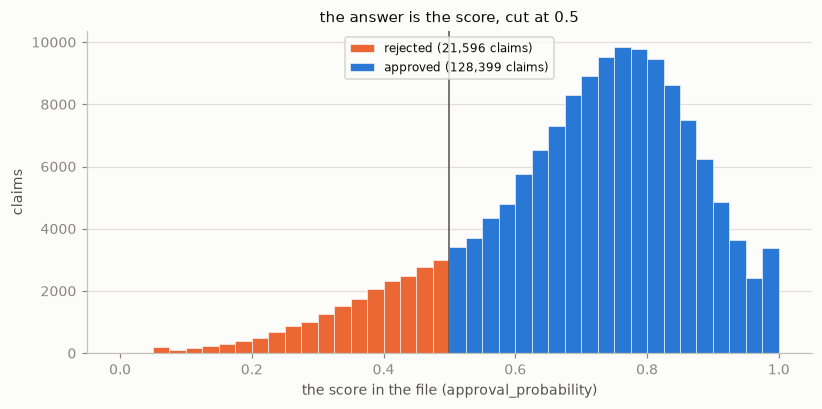

In [3]:
facts = claims.approval_rule_check(KIND)
scores = pd.read_csv(claims.raw_path(KIND), usecols=["record_id", "approval_probability", "claim_approved"]).drop_duplicates("record_id")
print(f"{facts['rows']:,} rows: in {facts['label_equals_rule']:.2f} % of them 'claim_approved' is exactly ('approval_probability' >= 0.5)")
figure, axis = plt.subplots(figsize=(8.5, 3.8))
bins = np.linspace(0, 1, 41)
for value, name, colour in ((0, "rejected", ORANGE), (1, "approved", BLUE)):
    part = scores.loc[scores["claim_approved"].astype(int) == value, "approval_probability"]
    axis.hist(part, bins=bins, color=colour, edgecolor=SURFACE, linewidth=0.4, label=f"{name} ({len(part):,} claims)")
axis.axvline(0.5, color=INK2, linewidth=1)
axis.set(xlabel="the score in the file (approval_probability)", ylabel="claims", title="the answer is the score, cut at 0.5")
axis.legend(loc="upper center")
tidy(axis, "y")
plt.show()

The answer is the score cut at 0.5, nothing else. The score itself is not something a customer has when a claim is filed: it is how
the dataset was made. If the model were allowed to see it, it would be right every time in this file and useless on the claim page.
So it is **never an input**. It is used once, in section 10, to find out how predictable the approval is.

## 3. What the data looks like
First the claim details that matter most. The line is the approval rate of all claims.

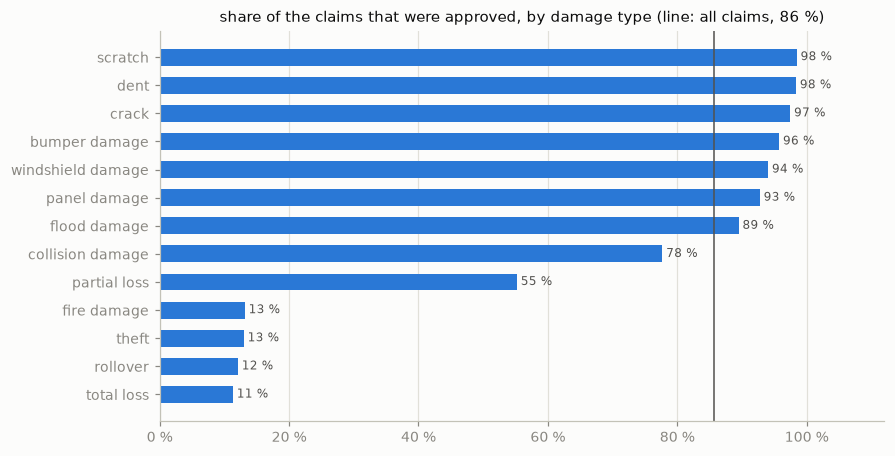

In [4]:
overall = 100 * data["approved"].mean()
figure, axis = plt.subplots(figsize=(8.5, 4.6))
by_type = (100 * data.groupby("damage_type")["approved"].mean()).sort_values()
axis.barh(by_type.index, by_type.values, color=BLUE, height=0.6)
for position, value in enumerate(by_type.values):
    axis.text(value, position, f" {value:.0f} %", va="center", fontsize=8, color=INK2)
axis.axvline(overall, color=INK2, linewidth=1)
axis.set_xlim(0, 112)
axis.xaxis.set_major_formatter(PERCENT)
axis.set_title(f"share of the claims that were approved, by damage type (line: all claims, {overall:.0f} %)")
tidy(axis, "x")
plt.show()

Then the other details, one picture each (same line, same scale). Each bar is the share of the claims of that group that were approved.

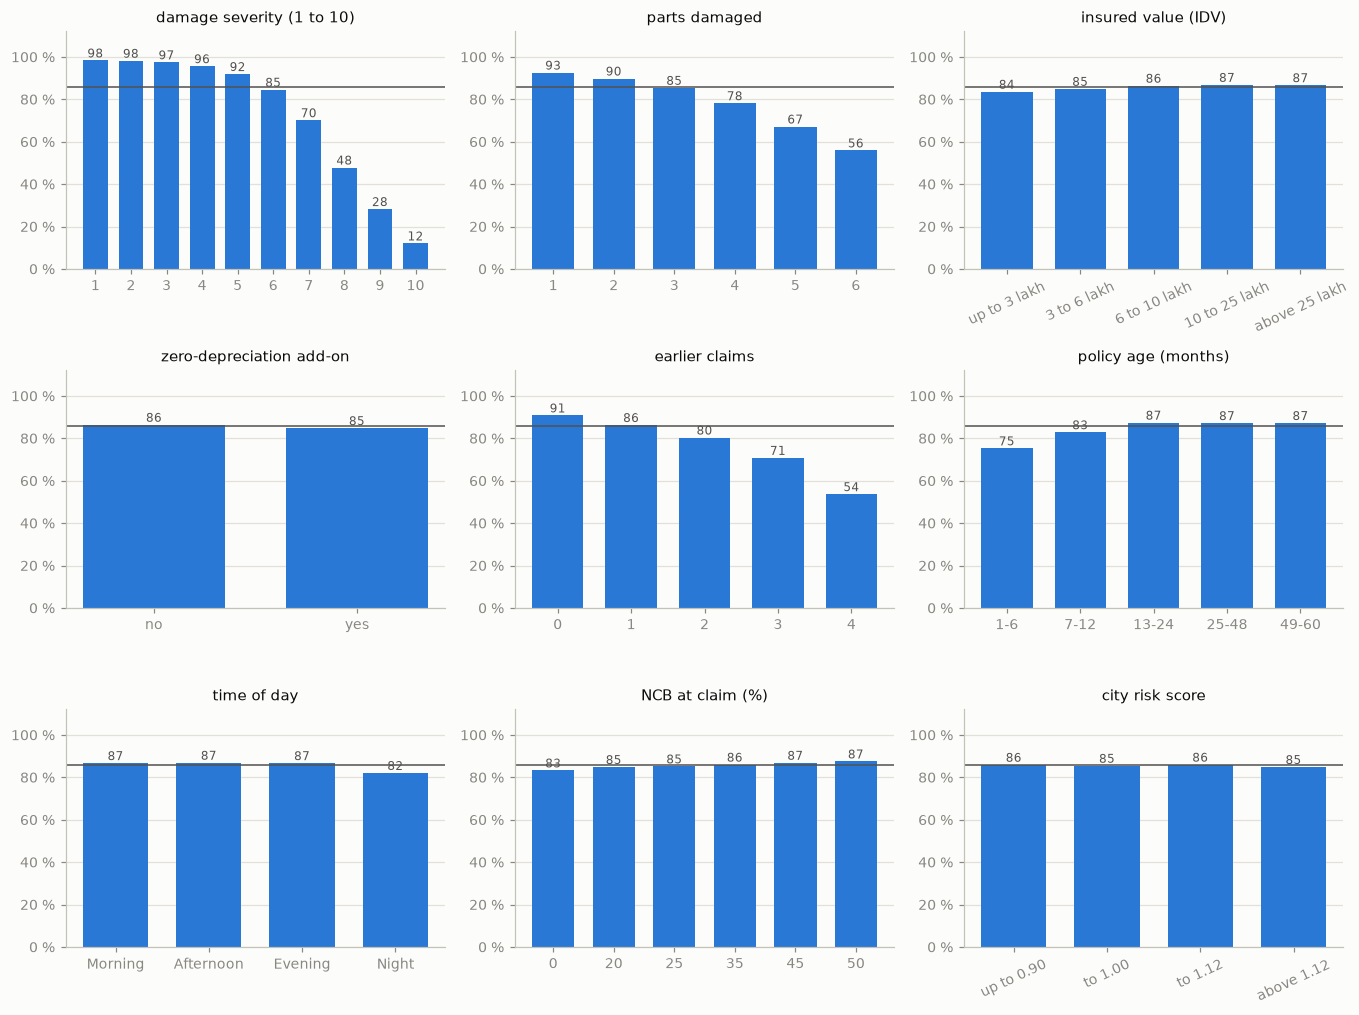

In [5]:
def banded(column, cuts, labels):
    """A number column cut into bands (the upper edge belongs to the band)."""
    return pd.cut(data[column], cuts, labels=labels)


idv_bands = claims.IDV_BANDS[KIND]
risk_cuts = [0.0] + [float(v) for v in data["city_risk_score"].quantile([0.25, 0.5, 0.75])] + [10.0]
panels = [
    ("damage severity (1 to 10)", data["damage_severity_score"], None),
    ("parts damaged", data["num_parts_affected"], None),
    ("insured value (IDV)", banded("idv", [low for low, _, _ in idv_bands] + [10 ** 12], [label for _, _, label in idv_bands]), None),
    ("zero-depreciation add-on", data["zero_dep_addon"].map({0: "no", 1: "yes"}), ["no", "yes"]),
    ("earlier claims", data["previous_claims_count"], None),
    ("policy age (months)", banded("policy_age_months", [0, 6, 12, 24, 48, 60], ["1-6", "7-12", "13-24", "25-48", "49-60"]), None),
    ("time of day", data["incident_time_of_day"], claims.TIMES_OF_DAY),
    ("NCB at claim (%)", data["ncb_at_claim_percent"], None),
    ("city risk score", banded("city_risk_score", risk_cuts, [f"up to {risk_cuts[1]:.2f}", f"to {risk_cuts[2]:.2f}", f"to {risk_cuts[3]:.2f}", f"above {risk_cuts[3]:.2f}"]), None),
]
rows_of_panels = math.ceil(len(panels) / 3)
figure, axes = plt.subplots(rows_of_panels, 3, figsize=(12.5, 3.1 * rows_of_panels))
panel_rates = {}
for axis, (title, groups, order) in zip(axes.ravel(), panels):
    table = 100 * data.groupby(groups, observed=True)["approved"].mean()
    if order is not None:
        table = table.reindex(order)
    panel_rates[title] = table
    axis.bar([str(label) for label in table.index], table.values, color=BLUE, width=0.7)
    for position, value in enumerate(table.values):
        axis.text(position, value, f"{value:.0f}", ha="center", va="bottom", fontsize=8, color=INK2)
    axis.axhline(overall, color=INK2, linewidth=1)
    axis.set_ylim(0, 112)
    axis.yaxis.set_major_formatter(PERCENT)
    axis.set_title(title)
    if sum(len(str(label)) for label in table.index) > 30:               # long labels are tilted
        axis.tick_params(axis="x", labelrotation=25)
    tidy(axis, "y")
for axis in axes.ravel()[len(panels):]:
    axis.set_visible(False)
figure.tight_layout()
plt.show()

In [6]:
def show(title, rates):
    return f"{title}: {rates.iloc[0]:.0f} % for {rates.index[0]}, {rates.iloc[-1]:.0f} % for {rates.index[-1]}"


spread = {title: rates.max() - rates.min() for title, rates in panel_rates.items()}
big = [show(title, panel_rates[title]) for title in spread if spread[title] >= 15]
some = [show(title, panel_rates[title]) for title in spread if 6 <= spread[title] < 15]
flat = [title for title in spread if spread[title] < 6]
low_types, mid_types = by_type[by_type < 30], by_type[(by_type >= 30) & (by_type < 90)]
display(Markdown(
    f"**Reading the pictures.** The damage type decides most: {', '.join(low_types.index)} are approved in only {low_types.min():.0f} to {low_types.max():.0f} % of the claims, "
    f"{', '.join(mid_types.index)} in {mid_types.min():.0f} to {mid_types.max():.0f} %, the other {len(by_type) - len(low_types) - len(mid_types)} types in {by_type[by_type >= 90].min():.0f} % or more. "
    f"Of the other details, the approval rate moves most with {'; '.join(big) or 'none'}. It moves less with {'; '.join(some) or 'none'}, "
    f"and by under 6 points between the highest and the lowest bar with {', '.join(flat) or 'none'}. "
    "A detail that barely moves the rate on its own can still matter in combination with others; that is what the model and the SHAP pictures (section 12) look at."))

**Reading the pictures.** The damage type decides most: total loss, rollover, theft, fire damage are approved in only 11 to 13 % of the claims, partial loss, collision damage, flood damage in 55 to 89 %, the other 6 types in 93 % or more. Of the other details, the approval rate moves most with damage severity (1 to 10): 98 % for 1, 12 % for 10; parts damaged: 93 % for 1, 56 % for 6; earlier claims: 91 % for 0, 54 % for 4. It moves less with policy age (months): 75 % for 1-6, 87 % for 49-60, and by under 6 points between the highest and the lowest bar with insured value (IDV), zero-depreciation add-on, time of day, NCB at claim (%), city risk score. A detail that barely moves the rate on its own can still matter in combination with others; that is what the model and the SHAP pictures (section 12) look at.

## 4. Train / test split
80 % of the claims are used to learn, 20 % are held back and only used to measure the result (`random_state` 42, so everyone gets
the same split).

In [7]:
train, test = claims.split_data(data)
X_train, y_train = claims.xy(train, KIND, TASK)
X_test, y_test = claims.xy(test, KIND, TASK)
print(f"{len(train):,} claims to learn from ({100 * y_train.mean():.1f} % approved), {len(test):,} claims held back for testing ({100 * y_test.mean():.1f} % approved)")
print("details the model uses:", ", ".join(claims.input_columns(KIND, TASK)))

119,996 claims to learn from (85.6 % approved), 29,999 claims held back for testing (85.6 % approved)
details the model uses: damage_type, damage_severity_score, num_parts_affected, idv, zero_dep_addon, previous_claims_count, policy_age_months, incident_time_of_day, ncb_at_claim_percent, city


## 5. Feature engineering
The model cannot read words, so `ClaimFeatures` (in `acko/claims.py`) turns the details of a claim into numbers:

| From the claim | Becomes |
|---|---|
| damage type, time of day (words) | a code number for each word, learned from the training claims |
| city | its **city risk score**: the risk score of that city in the training claims |
| skipped optional answers | the typical answer of the training claims (the more common word or yes/no answer, otherwise the middle value) |
| everything else | passed on unchanged (yes / no becomes 1 / 0) |

`fit()` learns the code numbers, the city risk scores and the typical answers from the **training claims only**. `transform()` then
needs nothing but the details of the claim itself. This is its code:

In [8]:
print(textwrap.dedent(inspect.getsource(claims.ClaimFeatures.transform)))

def transform(self, X) -> pd.DataFrame:
    X = pd.DataFrame(X).copy()
    for column, value in self.defaults_.items():            # optional details the customer skipped
        X[column] = X[column].fillna(value) if column in X.columns else value
    out = pd.DataFrame(index=X.index)
    for name in feature_names(self.kind, self.task):
        if name == "city_risk_score":      # no city given (or an unknown one) -> the typical city risk
            known = X["city"].map(self.city_risk_) if "city" in X.columns else pd.Series(np.nan, index=X.index)
            out[name] = known.fillna(self.risk_default_).astype(float)
        elif name in self.codes_:
            out[name] = X[name].map(self.codes_[name]).astype(float)       # unknown word -> missing (NaN)
        else:
            out[name] = X[name].astype(float)
    return out



In [9]:
features = claims.ClaimFeatures(KIND, TASK).fit(X_train)
shown = X_test.head(5)[claims.input_columns(KIND, TASK)]
print("Five test claims, as the customer gives them:")
display(shown)
print("The same five, as the model sees them:")
display(features.transform(shown).round(2))
print("Code numbers learned for the damage types:")
print({word: int(number) for word, number in features.codes_["damage_type"].items()})
print("Typical answers used when a question is skipped:")
print({name: (value if isinstance(value, str) else round(float(value), 1)) for name, value in features.defaults_.items()})
per_city = data.groupby("city")["city_risk_score"].nunique()
print(f"{len(per_city)} cities; each one has exactly one risk score in the data: {bool((per_city == 1).all())}")
assert (per_city == 1).all(), "a city must have one risk score, so that the city alone is enough on the claim page"

Five test claims, as the customer gives them:


,damage_type,damage_severity_score,num_parts_affected,idv,zero_dep_addon,previous_claims_count,policy_age_months,incident_time_of_day,ncb_at_claim_percent,city
128072,dent,3,1,1381739,1,3,27,Evening,35,Jammu
65515,dent,2,1,350553,1,0,32,Evening,45,Saharanpur
85046,dent,4,2,191513,0,0,4,Evening,45,Guntur
118189,crack,4,3,1347315,1,4,30,Evening,0,Vizianagaram
92366,crack,5,2,200185,0,0,49,Afternoon,35,Pimpri-Chinchwad


The same five, as the model sees them:


,damage_type,damage_severity_score,num_parts_affected,idv,zero_dep_addon,previous_claims_count,policy_age_months,incident_time_of_day,ncb_at_claim_percent,city_risk_score
128072,3.0,3.0,1.0,1381739.0,1.0,3.0,27.0,1.0,35.0,0.92
65515,3.0,2.0,1.0,350553.0,1.0,0.0,32.0,1.0,45.0,1.08
85046,3.0,4.0,2.0,191513.0,0.0,0.0,4.0,1.0,45.0,1.05
118189,2.0,4.0,3.0,1347315.0,1.0,4.0,30.0,1.0,0.0,0.88
92366,2.0,5.0,2.0,200185.0,0.0,0.0,49.0,0.0,35.0,1.18


Code numbers learned for the damage types:
{'bumper damage': 0, 'collision damage': 1, 'crack': 2, 'dent': 3, 'fire damage': 4, 'flood damage': 5, 'panel damage': 6, 'partial loss': 7, 'rollover': 8, 'scratch': 9, 'theft': 10, 'total loss': 11, 'windshield damage': 12}
Typical answers used when a question is skipped:
{'zero_dep_addon': 0.0, 'previous_claims_count': 0.0, 'policy_age_months': 30.0, 'incident_time_of_day': 'Morning', 'ncb_at_claim_percent': 35.0}
117 cities; each one has exactly one risk score in the data: True


Every city has one risk score in the data, so on the claim page the customer only names the city; the score comes from the table above.

## 6. Training
The model is a **gradient boosting** classifier (`HistGradientBoostingClassifier`): many small decision trees, each one correcting the
mistakes of the trees before it. The sum of their answers becomes a probability between 0 and 1. The damage type, the time of day
are real categories for the trees, not numbers on a scale.

Training stops by itself when 10 % of the training claims, kept aside inside the training data, show no more gain for 10 rounds in
a row (at most 1,000 rounds). This is the code of `fit()`:

In [10]:
print(textwrap.dedent(inspect.getsource(claims.ClaimApprovalModel.fit)))

def fit(self, X, y):
    X = pd.DataFrame(X)
    self.features_ = ClaimFeatures(self.kind, "approval").fit(X)
    self.booster_ = HistGradientBoostingClassifier(
        max_iter=MAX_ROUNDS, learning_rate=0.1, early_stopping=True, random_state=0,
        categorical_features=categorical_positions(self.kind, "approval"))
    self.booster_.fit(self.features_.transform(X), np.asarray(y, dtype=int))
    self.classes_ = self.booster_.classes_
    self.n_rounds_ = int(self.booster_.n_iter_)
    return self



In [11]:
started = time.time()
model = claims.build_model(KIND, TASK).fit(X_train, y_train)
print(f"trained in {time.time() - started:.1f} s, {model.n_rounds_} boosting rounds")

trained in 1.3 s, 110 boosting rounds


## 7. Results against the brief's targets
All numbers below are measured on the held-back test claims, which the model never saw while learning. A claim counts as "approved"
when its probability reaches the threshold (0.5 here).

In [12]:
metrics = claims.evaluate_approval(model, X_test, y_test)
a = metrics["at_threshold"]
display(pd.DataFrame(
    [["Accuracy", f"{100 * a['accuracy']:.1f} %", "share of the claims decided correctly"],
     ["F1, approved claims", f"{a['f1_approved']:.3f}", "balance of precision and recall for the approved claims"],
     ["F1, rejected claims", f"{a['f1_rejected']:.3f}", "the same for the rejected claims (the smaller group)"],
     ["F1, average of both", f"{a['f1_macro']:.3f}", "the two F1 values averaged (macro F1)"],
     ["Precision, approved", f"{100 * a['precision_approved']:.1f} %", "of the claims the model approves, the share that really were approved"],
     ["Recall, approved", f"{100 * a['recall_approved']:.1f} %", "of the claims that really were approved, the share the model approves"],
     ["AUC", f"{a['auc']:.3f}", "chance that a really approved claim gets a higher probability than a really rejected one (0.5 = guessing, 1 = always)"]],
    columns=["measure", f"{a['n']:,} test claims", "what it says"]).set_index("measure"))
met = a["accuracy"] > claims.TARGET_ACCURACY and a["f1_macro"] > claims.TARGET_F1
print(f"brief: accuracy above {100 * claims.TARGET_ACCURACY:.0f} % and F1 above {claims.TARGET_F1}   ->   accuracy {100 * a['accuracy']:.1f} %, "
      f"F1 (average of both classes) {a['f1_macro']:.3f}   ->   {'MET' if met else 'NOT MET'}")
assert met, "The model misses the brief's targets"
for name, value in (("approved", a["f1_approved"]), ("rejected", a["f1_rejected"])):
    if value < claims.TARGET_F1:
        display(Markdown(f"**Read this honestly:** the brief does not say which F1 it means. The average of both classes ({a['f1_macro']:.3f}) is above 0.80, "
                         f"but the F1 of the **{name}** claims alone is **{value:.3f}**, below 0.80. Sections 9 and 10 show how much of that gap this data allows."))

,"29,999 test claims",what it says
measure,,
Accuracy,94.2 %,share of the claims decided correctly
"F1, approved claims",0.966,balance of precision and recall for the approv...
"F1, rejected claims",0.792,the same for the rejected claims (the smaller ...
"F1, average of both",0.879,the two F1 values averaged (macro F1)
"Precision, approved",96.2 %,"of the claims the model approves, the share th..."
"Recall, approved",97.0 %,"of the claims that really were approved, the s..."
AUC,0.973,chance that a really approved claim gets a hig...


brief: accuracy above 80 % and F1 above 0.8   ->   accuracy 94.2 %, F1 (average of both classes) 0.879   ->   MET


**Read this honestly:** the brief does not say which F1 it means. The average of both classes (0.879) is above 0.80, but the F1 of the **rejected** claims alone is **0.792**, below 0.80. Sections 9 and 10 show how much of that gap this data allows.

Three pictures of the same result: what the model decided against what really happened, how well it ranks the claims, and whether its
probabilities can be trusted.

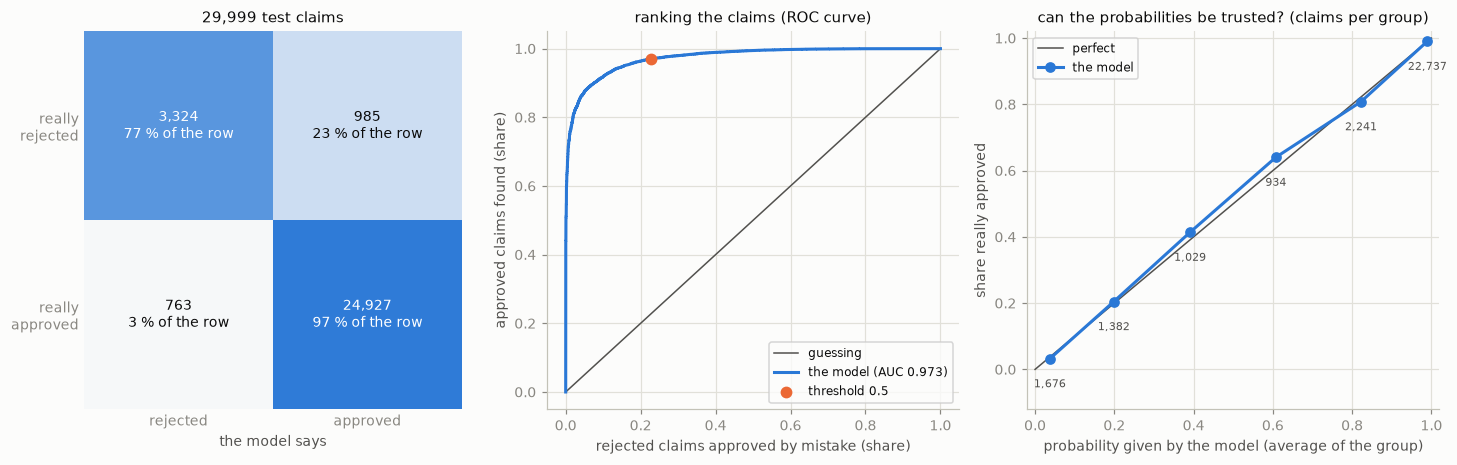

In [13]:
probability = model.approval_probability(X_test)
(tn, fp), (fn, tp) = a["confusion"]
figure, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))

counts = np.array([[tn, fp], [fn, tp]])
shares = counts / counts.sum(axis=1, keepdims=True)
axes[0].imshow(shares, cmap=LinearSegmentedColormap.from_list("blues", [SURFACE, BLUE]), vmin=0, vmax=1)
for row in range(2):
    for column in range(2):
        axes[0].text(column, row, f"{counts[row, column]:,}\n{100 * shares[row, column]:.0f} % of the row", ha="center", va="center", fontsize=9,
                     color="white" if shares[row, column] > 0.55 else INK)
axes[0].set_xticks([0, 1], ["rejected", "approved"])
axes[0].set_yticks([0, 1], ["really\nrejected", "really\napproved"])
axes[0].set(xlabel="the model says", title=f"{len(y_test):,} test claims")
axes[0].grid(False)
axes[0].spines[:].set_visible(False)
axes[0].tick_params(length=0)

fpr, tpr, _ = roc_curve(y_test, probability)
axes[1].plot([0, 1], [0, 1], color=INK2, linewidth=1, label="guessing")
axes[1].plot(fpr, tpr, color=BLUE, linewidth=2, label=f"the model (AUC {a['auc']:.3f})")
axes[1].scatter([fp / (fp + tn)], [tp / (tp + fn)], color=ORANGE, s=45, zorder=3, label=f"threshold {a['threshold']:g}")
axes[1].set(xlabel="rejected claims approved by mistake (share)", ylabel="approved claims found (share)", title="ranking the claims (ROC curve)")
axes[1].legend(loc="lower right")
tidy(axes[1], "both")

calibration = metrics["calibration"]
axes[2].plot([0, 1], [0, 1], color=INK2, linewidth=1, label="perfect")
axes[2].plot([row["predicted"] for row in calibration], [row["actual"] for row in calibration], color=BLUE, linewidth=2, marker="o", label="the model")
for row in calibration:
    axes[2].text(row["predicted"], row["actual"] - 0.06, f"{row['n']:,}", ha="center", va="top", fontsize=7.5, color=INK2)
axes[2].set(xlabel="probability given by the model (average of the group)", ylabel="share really approved", title="can the probabilities be trusted? (claims per group)")
axes[2].set_xlim(-0.02, 1.02)
axes[2].set_ylim(-0.12, 1.02)
axes[2].legend(loc="upper left")
tidy(axes[2], "both")
figure.tight_layout()
plt.show()

In [14]:
off = [abs(row["predicted"] - row["actual"]) for row in calibration]
display(Markdown(
    f"Of the {a['n']:,} test claims the model put {tp:,} approved claims above the threshold and {tn:,} rejected claims below it. It put {fp:,} rejected claims above it "
    f"({100 * fp / (fp + tn):.0f} % of the rejected ones, they would be approved at once) and {fn:,} approved claims below it ({100 * fn / (fn + tp):.0f} % of the approved ones, "
    f"they would go to a person). The probabilities can be trusted: in every group of the third picture the share of claims that really were approved is within "
    f"{100 * max(off):.1f} points of the probability the model gave."))

Of the 29,999 test claims the model put 24,927 approved claims above the threshold and 3,324 rejected claims below it. It put 985 rejected claims above it (23 % of the rejected ones, they would be approved at once) and 763 approved claims below it (3 % of the approved ones, they would go to a person). The probabilities can be trusted: in every group of the third picture the share of claims that really were approved is within 3.3 points of the probability the model gave.

## 8. The approval threshold
The brief asks for a **configurable threshold, 0.5 by default**. A claim whose probability reaches the threshold is approved; every
other claim goes to a person for review. Moving the threshold trades one kind of mistake for the other:

In [15]:
rows = []
for t in metrics["thresholds"]:
    (t_tn, t_fp), (t_fn, t_tp) = t["confusion"]
    rows.append({"threshold": t["threshold"], "accuracy": f"{100 * t['accuracy']:.1f} %", "F1 approved": round(t["f1_approved"], 3),
                 "F1 rejected": round(t["f1_rejected"], 3), "claims approved at once": f"{100 * t['predicted_approved_rate']:.1f} %",
                 "rejected claims approved by mistake": f"{100 * t_fp / (t_fp + t_tn):.1f} %",
                 "approved claims sent to a person": f"{100 * t_fn / (t_fn + t_tp):.1f} %"})
display(pd.DataFrame(rows).set_index("threshold"))

,accuracy,F1 approved,F1 rejected,claims approved at once,rejected claims approved by mistake,approved claims sent to a person
threshold,,,,,,
0.3,93.6 %,0.963,0.739,89.8 %,36.9 %,1.3 %
0.4,94.0 %,0.966,0.775,87.9 %,28.6 %,2.2 %
0.5,94.2 %,0.966,0.792,86.4 %,22.9 %,3.0 %
0.6,94.0 %,0.965,0.794,85.0 %,18.9 %,3.9 %
0.7,93.3 %,0.960,0.785,83.3 %,15.1 %,5.3 %
0.8,92.0 %,0.952,0.762,80.7 %,10.7 %,7.5 %


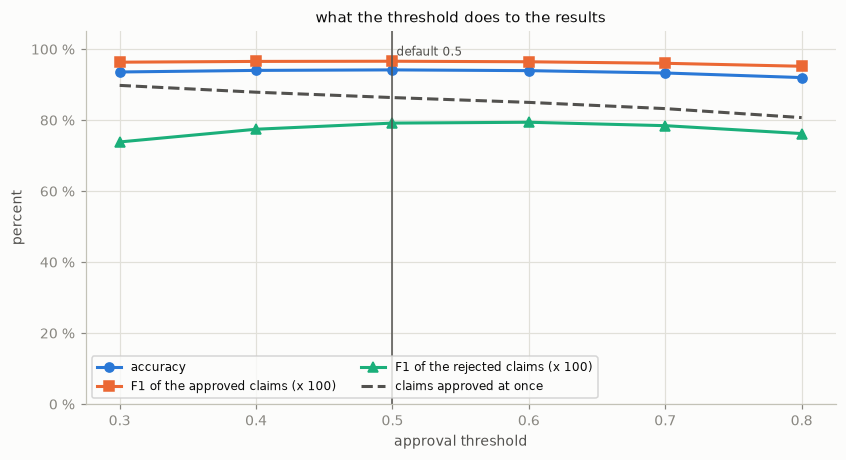

In [16]:
figure, axis = plt.subplots(figsize=(8.8, 4.4))
levels = [t["threshold"] for t in metrics["thresholds"]]
lines = (("accuracy", [100 * t["accuracy"] for t in metrics["thresholds"]], BLUE, "o", "-"),
         ("F1 of the approved claims (x 100)", [100 * t["f1_approved"] for t in metrics["thresholds"]], ORANGE, "s", "-"),
         ("F1 of the rejected claims (x 100)", [100 * t["f1_rejected"] for t in metrics["thresholds"]], AQUA, "^", "-"),
         ("claims approved at once", [100 * t["predicted_approved_rate"] for t in metrics["thresholds"]], INK2, "", "--"))
for name, values, colour, marker, style in lines:
    axis.plot(levels, values, color=colour, linewidth=2, marker=marker, linestyle=style, label=name)
axis.axvline(config.APPROVAL_THRESHOLD, color=INK2, linewidth=1)
axis.text(config.APPROVAL_THRESHOLD, 101, f" default {config.APPROVAL_THRESHOLD:g}", color=INK2, fontsize=8, va="top")
axis.set(xlabel="approval threshold", ylabel="percent", title="what the threshold does to the results", ylim=(0, 105))
axis.set_xticks(levels)
axis.yaxis.set_major_formatter(PERCENT)
axis.legend(loc="lower left", ncols=2)
tidy(axis, "both")
plt.show()

In [17]:
def mistakes(t):
    (m_tn, m_fp), (m_fn, m_tp) = t["confusion"]
    return 100 * m_fp / (m_fp + m_tn), 100 * m_fn / (m_fn + m_tp)


standard = min(metrics["thresholds"], key=lambda t: abs(t["threshold"] - config.APPROVAL_THRESHOLD))
strict = metrics["thresholds"][-1]
best = max(metrics["thresholds"], key=lambda t: t["accuracy"])
slip_standard, sent_standard = mistakes(standard)
slip_strict, sent_strict = mistakes(strict)
display(Markdown(
    f"At the default threshold of {standard['threshold']:g}, {100 * standard['predicted_approved_rate']:.0f} % of the claims are approved at once; {slip_standard:.0f} % of the rejected claims "
    f"are approved by mistake and {sent_standard:.0f} % of the approved claims are sent to a person. At {strict['threshold']:g}, {slip_strict:.0f} % of the rejected claims slip through, but "
    f"{sent_strict:.0f} % of the approved claims go to a person. The accuracy is highest at a threshold of {best['threshold']:g}. No threshold removes both kinds of mistake, "
    "so the threshold is a business choice: how many wrong approvals the insurer accepts against how many claims a person must look at. It is a setting "
    "(`APPROVAL_THRESHOLD`), and a manager can change it on the claim page."))

At the default threshold of 0.5, 86 % of the claims are approved at once; 23 % of the rejected claims are approved by mistake and 3 % of the approved claims are sent to a person. At 0.8, 11 % of the rejected claims slip through, but 8 % of the approved claims go to a person. The accuracy is highest at a threshold of 0.5. No threshold removes both kinds of mistake, so the threshold is a business choice: how many wrong approvals the insurer accepts against how many claims a person must look at. It is a setting (`APPROVAL_THRESHOLD`), and a manager can change it on the claim page.

## 9. Why gradient boosting
The same test claims, decided three ways. The first two are simple on purpose.

In [18]:
rows = claims.approval_baselines(KIND, X_train, y_train, X_test, y_test, model)
display(pd.DataFrame([{"method": r["name"], "accuracy": f"{100 * r['accuracy']:.1f} %", "F1 approved": round(r["f1_approved"], 3),
                       "F1 rejected": round(r["f1_rejected"], 3), "F1 average": round(r["f1_macro"], 3), "AUC": round(r["auc"], 3)}
                      for r in rows]).set_index("method"))
everything, logistic = rows[0], rows[1]
assert all(a[name] > logistic[name] for name in ("accuracy", "f1_approved", "f1_rejected", "auc")), "The text below says that boosting is better on every measure; check it."
display(Markdown(f"Approving every claim is right {100 * everything['accuracy']:.1f} % of the time, only because most claims are approved; it never "
                 f"finds a rejected claim (F1 {everything['f1_rejected']:.3f}). Straight-line rules (logistic regression) reach {100 * logistic['accuracy']:.1f} % "
                 f"and an F1 of {logistic['f1_rejected']:.3f} on the rejected claims; gradient boosting reaches {100 * a['accuracy']:.1f} % and {a['f1_rejected']:.3f}, "
                 "and it is better on every measure of the table."))

,accuracy,F1 approved,F1 rejected,F1 average,AUC
method,,,,,
Approve every claim,85.6 %,0.923,0.000,0.461,0.500
Logistic regression (straight-line rules),93.4 %,0.962,0.757,0.860,0.963
Gradient boosting (this project's model),94.2 %,0.966,0.792,0.879,0.973


Approving every claim is right 85.6 % of the time, only because most claims are approved; it never finds a rejected claim (F1 0.000). Straight-line rules (logistic regression) reach 93.4 % and an F1 of 0.757 on the rejected claims; gradient boosting reaches 94.2 % and 0.792, and it is better on every measure of the table.

## 10. How predictable is the approval at all?
The score from section 2 helps here as a measuring stick, never as an input. A second model is trained on the same claim details
but to predict the **score** (not the answer), and its predictions are cut at 0.5. How much of the score's ups and downs can the
claim details explain, and how often does that give the right answer?

In [19]:
ceiling = claims.approval_ceiling(KIND, train, test)
print(f"the claim details explain {100 * ceiling['r2']:.1f} % of the ups and downs of the hidden score (R2 {ceiling['r2']:.3f}) on {ceiling['rows']:,} test claims")
print(f"the score predicted from them, cut at 0.5, gives the right answer for {100 * ceiling['accuracy']:.1f} % of the claims")
print(f"the approval model above: {100 * a['accuracy']:.1f} %")
assert ceiling["accuracy"] - a["accuracy"] < 0.01, "The text below says that the classifier is close to this check; check it."
explained = round(100 * ceiling["r2"])
display(Markdown(
    f"The claim details explain {explained} % of the ups and downs of the hidden score; the other {100 - explained} % is not explained by them. "
    f"A model that is trained on the score itself (it is told more than the answer tells it) and then cut at 0.5 ends at {100 * ceiling['accuracy']:.1f} %, against "
    f"{100 * a['accuracy']:.1f} % for our classifier. This does not prove that no other model could do better, but it is a strong sign that most of the remaining "
    f"{100 - 100 * a['accuracy']:.1f} % of mistakes comes from the part of the score that these columns do not explain, so it cannot be learned from them."))

the claim details explain 77.5 % of the ups and downs of the hidden score (R2 0.775) on 29,999 test claims
the score predicted from them, cut at 0.5, gives the right answer for 94.2 % of the claims
the approval model above: 94.2 %


The claim details explain 78 % of the ups and downs of the hidden score; the other 22 % is not explained by them. A model that is trained on the score itself (it is told more than the answer tells it) and then cut at 0.5 ends at 94.2 %, against 94.2 % for our classifier. This does not prove that no other model could do better, but it is a strong sign that most of the remaining 5.8 % of mistakes comes from the part of the score that these columns do not explain, so it cannot be learned from them.

## 11. Would more columns help?
The claims file has more columns than the model uses (the state, the make and model, the year, the premium paid, the day of the week
and so on). The test: give the same kind of model **every other column** of the file, except the answers, the hidden score and the
date, and measure it on the same test claims.

In [20]:
raw = pd.read_csv(claims.raw_path(KIND)).drop_duplicates("record_id").set_index("record_id")
used = set(claims.input_columns(KIND, TASK)) | set(claims.feature_names(KIND, TASK)) | set(claims.lookup_columns(TASK))
never = {"claim_amount", "claim_approved", "approval_probability", "affected_parts", "incident_date"}       # answers, a hidden score, a list of words, a date
extra = [column for column in raw.columns if column not in used | never]
words = [column for column in extra if not pd.api.types.is_numeric_dtype(raw[column])]
print(f"{len(extra)} more columns ({len(words)} of them hold words): {', '.join(extra)}")

15 more columns (7 of them hold words): customer_age, state, city_tier, vehicle_make, vehicle_model, segment, engine_cc, manufacturing_year, vehicle_age_years, policy_type, annual_premium_paid, engine_protection_addon, incident_day_of_week, incident_month, incident_type


In [21]:
more_train = raw.loc[train["record_id"], extra].reset_index(drop=True)
more_test = raw.loc[test["record_id"], extra].reset_index(drop=True)
for column in words:                                    # words -> code numbers, learned from the training claims only
    codes = {word: number for number, word in enumerate(sorted(more_train[column].dropna().unique()))}
    more_train[column] = more_train[column].map(codes).astype(float)
    more_test[column] = more_test[column].map(codes).astype(float)
learn = pd.concat([model.features_.transform(X_train).reset_index(drop=True), more_train.astype(float)], axis=1)
check = pd.concat([model.features_.transform(X_test).reset_index(drop=True), more_test.astype(float)], axis=1)
is_category = [column in claims.CATEGORY_COLUMNS or column in words for column in learn.columns]
wide = HistGradientBoostingClassifier(max_iter=claims.MAX_ROUNDS, learning_rate=0.1, early_stopping=True, random_state=0,
                                      categorical_features=is_category)
wide.fit(learn, y_train.to_numpy(dtype=int))
wide_score = claims.score_approval(y_test, wide.predict_proba(check)[:, 1])
display(pd.DataFrame(
    [{"model": f"the {len(claims.input_columns(KIND, TASK))} details we use", "accuracy": f"{100 * a['accuracy']:.1f} %", "F1 rejected": round(a["f1_rejected"], 3),
      "F1 average": round(a["f1_macro"], 3), "AUC": round(a["auc"], 3)},
     {"model": f"the same plus {len(extra)} more columns", "accuracy": f"{100 * wide_score['accuracy']:.1f} %", "F1 rejected": round(wide_score["f1_rejected"], 3),
      "F1 average": round(wide_score["f1_macro"], 3), "AUC": round(wide_score["auc"], 3)}]).set_index("model"))

,accuracy,F1 rejected,F1 average,AUC
model,,,,
the 10 details we use,94.2 %,0.792,0.879,0.973
the same plus 15 more columns,93.9 %,0.781,0.873,0.971


In [22]:
assert wide_score["accuracy"] < a["accuracy"] + 0.005, "The text below says that the extra columns do not help; check it."
display(Markdown(f"With {len(extra)} more columns the accuracy is {100 * wide_score['accuracy']:.1f} % (with the {len(claims.input_columns(KIND, TASK))} details: {100 * a['accuracy']:.1f} %) and the F1 of the "
                 f"rejected claims {wide_score['f1_rejected']:.3f} (with the details: {a['f1_rejected']:.3f}). The extra columns do not make the decisions better, so this test finds "
                 "nothing in them that helps with the approval. Keeping the model to these details also keeps the claim page short."))

With 15 more columns the accuracy is 93.9 % (with the 10 details: 94.2 %) and the F1 of the rejected claims 0.781 (with the details: 0.792). The extra columns do not make the decisions better, so this test finds nothing in them that helps with the approval. Keeping the model to these details also keeps the claim page short.

## 12. SHAP: why does the model give this probability?
SHAP answers: "for this claim, how much did each detail push the probability up or down?" It starts from a **typical claim** and gives
every detail its share of the difference, so that

    typical probability + the push of every detail = the model's probability, exactly.

Two choices, both explained in `acko/claims_explain.py`:

- The answer that is explained is the **probability** (0 to 1). A push of 0.10 is 10 percentage points.
- SHAP's fast `TreeExplainer` is **not** used. These trees split on categories (damage type, time of day), and for such splits its
  pieces do not add up to the model's answer; the check below shows by how much. SHAP's `Permutation` explainer only asks the model
  questions, so it is exact for any model. It is slower, which is why 300 test claims are explained, not all of them.

In [23]:
background = explain.background_claims(model, TASK, X_train)          # 100 training claims that stand for a typical claim
sample = X_test.sample(explain.N_EXPLAINED, random_state=0)           # 300 test claims to explain
result = explain.explain(model, TASK, background, sample)
add_gap = explain.additivity_gap(result)
print(f"SHAP values for {len(sample)} test claims, computed in {result.seconds:.0f} s")
print(f"typical probability of approval: {100 * result.base:.1f} %;   largest gap between 'typical + pushes' and the model's own probability: {add_gap:.1e}")
assert add_gap < 1e-9, "the pieces must add up to the model's answer"

SHAP values for 300 test claims, computed in 57 s
typical probability of approval: 85.3 %;   largest gap between 'typical + pushes' and the model's own probability: 2.6e-15


In [24]:
# For comparison: SHAP's fast TreeExplainer on the same claims. It runs without an error, but its pieces do not add up.
try:
    tree = shap.TreeExplainer(model.booster_)
    tree_pieces = np.asarray(tree.shap_values(result.table))
    tree_gap = float(np.abs(np.ravel(tree.expected_value)[0] + tree_pieces.sum(axis=1) - model.booster_.decision_function(result.table)).max())
    print(f"TreeExplainer: largest gap between 'typical + pieces' and the model's own answer: {tree_gap:.1f} on the model's log-odds scale "
          f"(the Permutation explainer above: {add_gap:.0e} on the probability scale)")
except Exception as problem:
    print("TreeExplainer could not be used on this model:", type(problem).__name__)

TreeExplainer: largest gap between 'typical + pieces' and the model's own answer: 13.2 on the model's log-odds scale (the Permutation explainer above: 3e-15 on the probability scale)


**Which details matter most.** The bars show how far each detail moves the probability on average, in percentage points. The picture is
saved in `reports/shap/`.

saved: reports/shap/claims_car_approval_importance.png


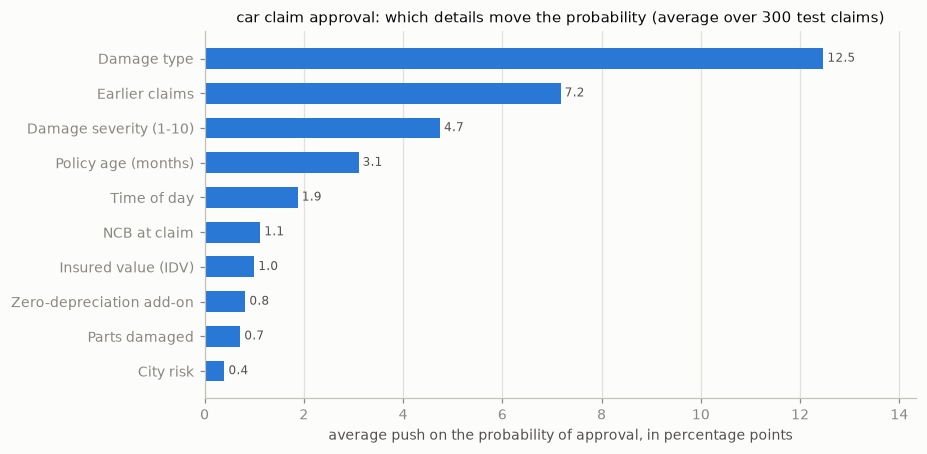

In [25]:
figure, axis = plt.subplots(figsize=(8.5, 4.2))
explain.draw_importance(axis, result, "average push on the probability of approval, in percentage points")
axis.set_title(f"car claim approval: which details move the probability (average over {len(sample)} test claims)")
figure.tight_layout()
print("saved: reports/shap/" + explain.save_figure(figure, f"claims_{KIND}_{TASK}_importance.png").name)
plt.show()

**Every test claim as a dot.** Left of the middle line the detail lowers the probability, right of it raises it. The colour is the value
of the detail: red = high, blue = low. For the damage type, "high" means a type that is approved more often: the types are coloured in
the order of their approval rate (`claims_explain.colour_codes`).

saved: reports/shap/claims_car_approval_summary.png


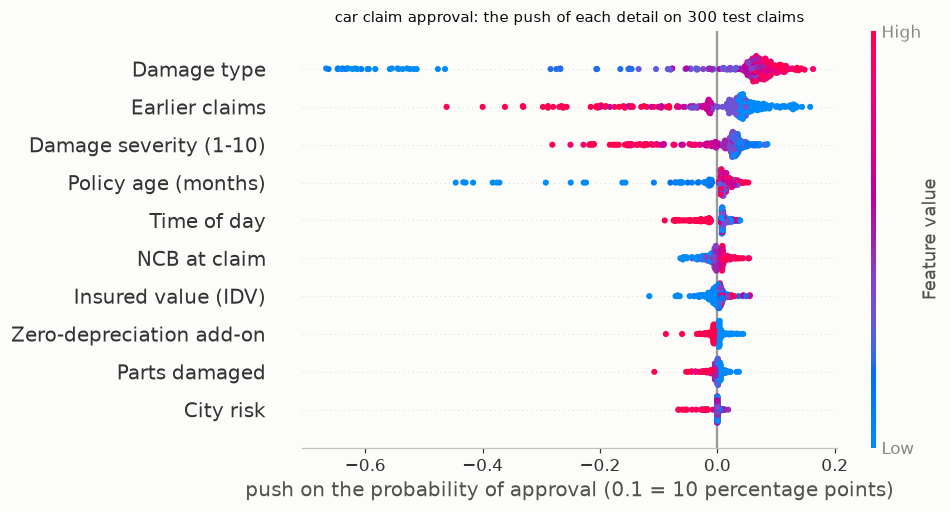

In [26]:
damage_order = list(data.groupby("damage_type")["approved"].mean().sort_values().index)        # least approved damage type first
shap.summary_plot(result.values, explain.colour_codes(model, result.table, damage_order), feature_names=result.labels, show=False,
                  max_display=len(result.names), plot_size=(9, 4.6))
plt.xlabel("push on the probability of approval (0.1 = 10 percentage points)")
plt.title(f"car claim approval: the push of each detail on {len(sample)} test claims")
print("saved: reports/shap/" + explain.save_figure(plt.gcf(), f"claims_{KIND}_{TASK}_summary.png").name)
plt.show()

**Two claims, step by step.** The first claim is the one in the sample whose probability is closest to 25 % (it goes to a person), the
second the one closest to 75 % (it is approved at the default threshold). The grey bar on the left is the probability of a typical
claim; each coloured bar is what one detail adds (blue) or takes off (orange), from the biggest push to the smallest; the grey bar on
the right is the model's probability.

claim with probability 25.7 % -> review:   typical 85.3 %  +  the pushes -59.6  =  25.7 %


,this claim,push (points)
detail,,
Damage severity (1-10),8 of 10,-25.0
Earlier claims,2,-14.9
Damage type,collision damage,-10.5
Zero-depreciation add-on,yes,-8.8
Time of day,Night,-6.2
Insured value (IDV),"₹40,26,697",+5.6
Parts damaged,6,-2.8
Other columns,3 columns,+3.0


claim with probability 74.9 % -> approved:   typical 85.3 %  +  the pushes -10.4  =  74.9 %


,this claim,push (points)
detail,,
Earlier claims,3,-17.5
Damage type,dent,+16.3
Policy age (months),8 months,-6.5
NCB at claim,0 %,-3.7
Damage severity (1-10),4 of 10,+3.0
Insured value (IDV),"₹2,18,860",-2.4
Time of day,Morning,+2.2
Other columns,3 columns,-1.8


saved: reports/shap/claims_car_approval_example.png


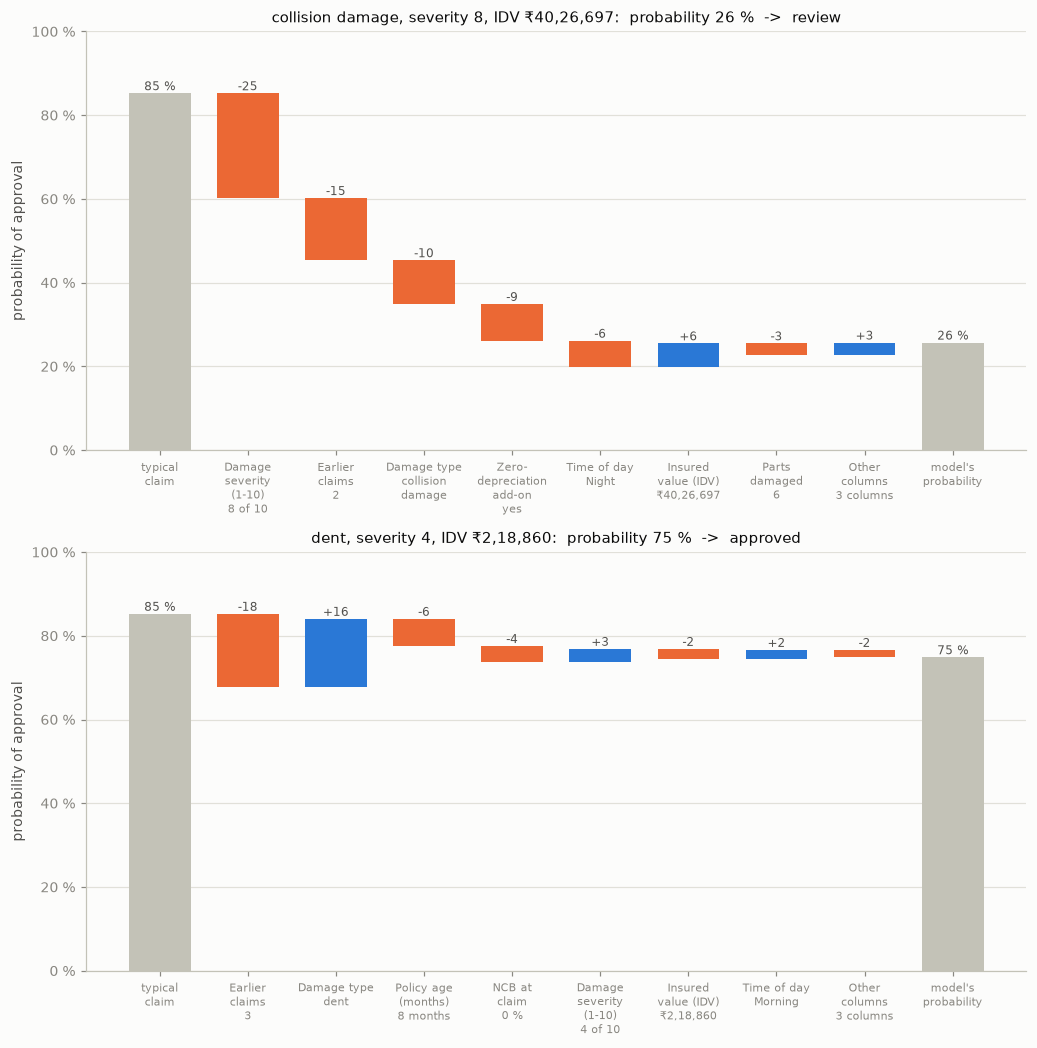

In [27]:
picks = [int(np.argmin(np.abs(result.output - wanted))) for wanted in (0.25, 0.75)]
figure, axes = plt.subplots(2, 1, figsize=(9.5, 9.6))
for axis, position in zip(axes, picks):
    row = sample.iloc[position]
    steps, start, end = explain.example_steps(result, position, row)
    table = pd.DataFrame([{"detail": label, "this claim": detail, "push (points)": f"{value:+.1f}"} for label, detail, value in steps]).set_index("detail")
    print(f"claim with probability {end:.1f} % -> {claims.status_for(end / 100)}:   typical {start:.1f} %  +  the pushes {sum(value for _, _, value in steps):+.1f}  =  {end:.1f} %")
    display(table)
    assert abs(start + sum(value for _, _, value in steps) - end) < 1e-6
    explain.draw_waterfall(axis, steps, start, end, "typical\nclaim", "model's\nprobability", money=False)
    axis.set_yticks([tick for tick in axis.get_yticks() if 0 <= tick <= 100])          # a probability stops at 100 %
    axis.set_title(f"{row['damage_type']}, severity {int(row['damage_severity_score'])}, IDV {inr(row['idv'])}:  probability {end:.0f} %  ->  {claims.status_for(end / 100)}")
    axis.set_ylabel("probability of approval")
figure.tight_layout()
print("saved: reports/shap/" + explain.save_figure(figure, f"claims_{KIND}_{TASK}_example.png").name)
plt.show()

## 13. Checking the saved `.pkl` file
The claim page does not train anything: it loads `models/claim_car_approval.pkl`. This step opens that file and checks that it gives
the same answers as the model trained above, and that it meets the brief's targets on its own.

In [28]:
try:
    bundle = claims.load_bundle(KIND, TASK)
except claims.ModelMissing as problem:
    bundle = None
    print(problem)
if bundle is not None:
    saved = bundle["model"]
    path = claims.MODEL_FILES[(KIND, TASK)]
    saved_score = claims.evaluate_approval(saved, X_test, y_test)["at_threshold"]
    difference = float(np.abs(saved.approval_probability(X_test) - probability).max())
    print(f"file: models/{path.name} ({path.stat().st_size / 1e6:.2f} MB), trained {bundle['trained_at']}, scikit-learn {bundle['versions']['scikit-learn']}")
    print(f"accuracy of the saved model on the test claims: {100 * saved_score['accuracy']:.1f} %, F1 average {saved_score['f1_macro']:.3f}   "
          f"(trained here: {100 * a['accuracy']:.1f} %, {a['f1_macro']:.3f})")
    print(f"largest difference between the probabilities of the saved model and the one trained here: {difference:.2e}   (0: the same model)")
    assert saved_score["accuracy"] > claims.TARGET_ACCURACY and saved_score["f1_macro"] > claims.TARGET_F1

file: models/claim_car_approval.pkl (0.18 MB), trained 2026-11-14 16:43, scikit-learn 1.9.1
accuracy of the saved model on the test claims: 94.2 %, F1 average 0.879   (trained here: 94.2 %, 0.879)
largest difference between the probabilities of the saved model and the one trained here: 0.00e+00   (0: the same model)


And the way the claim page uses the model: one claim in, a probability and a status out, and the threshold can be changed. Details that
are skipped get typical values.

In [29]:
if bundle is not None:
    engine = claims.ClaimEngine.load()
    case = dict(kind="car", damage_type="collision damage", severity_score=7, num_parts=3, idv=800_000, zero_dep=1, previous_claims=1,
                policy_age_months=24, time_of_day="Night", ncb=20)
    print("car, collision damage, severity 7, 3 parts, IDV Rs 8,00,000, 1 earlier claim, policy 24 months old, at night, NCB 20 %:")
    for threshold in (0.5, 0.7):
        estimate = engine.estimate(**case, threshold=threshold)
        print(f"   threshold {threshold:g}:  approval probability {100 * estimate.probability:.1f} %  ->  {estimate.status}")

car, collision damage, severity 7, 3 parts, IDV Rs 8,00,000, 1 earlier claim, policy 24 months old, at night, NCB 20 %:
   threshold 0.5:  approval probability 68.1 %  ->  approved
   threshold 0.7:  approval probability 68.1 %  ->  review


## Summary and limits

In [30]:
if a["f1_rejected"] < claims.TARGET_F1:
    f1_note = (f"The F1 of the rejected claims alone is {a['f1_rejected']:.3f}, below 0.80. The brief does not say which F1 it means; the average of both classes "
               f"({a['f1_macro']:.3f}) and the F1 of the approved claims ({a['f1_approved']:.3f}) are above 0.80, the F1 of the smaller group is not. Sections 9 and 10 show what the file allows.")
else:
    f1_note = f"The F1 of both classes is above 0.80 (approved {a['f1_approved']:.3f}, rejected {a['f1_rejected']:.3f})."
display(Markdown(f"""
**Car claim approval model**

| | |
|---|---|
| model | gradient boosting classifier (`HistGradientBoostingClassifier`), {model.n_rounds_} rounds |
| test claims | {a['n']:,} ({100 * a['approved_rate']:.1f} % approved) |
| accuracy | {100 * a['accuracy']:.1f} % (brief: above {100 * claims.TARGET_ACCURACY:.0f} %) |
| F1 | {a['f1_macro']:.3f} averaged over both classes (approved {a['f1_approved']:.3f}, rejected {a['f1_rejected']:.3f}); brief: above {claims.TARGET_F1} |
| AUC | {a['auc']:.3f} |
| targets | {'MET' if met else 'NOT MET'} (accuracy and F1 averaged over both classes) |
| threshold | {config.APPROVAL_THRESHOLD:g} by default (`APPROVAL_THRESHOLD`), a manager can change it on the claim page |
| saved model | `models/claim_car_approval.pkl` |
| SHAP pictures | `reports/shap/claims_car_approval_importance.png`, `_summary.png`, `_example.png` |
| run time of this notebook | {(time.time() - STARTED) / 60:.1f} minutes |

**Limits you should know about**

- The data is synthetic. The model learns the rules of this dataset, not those of real Acko claims.
- {f1_note}
- The answer in the file was made from a hidden score, and the claim details explain {explained} % of that score (section 10). A model trained on the score
  itself reaches {100 * ceiling['accuracy']:.1f} % accuracy, ours {100 * a['accuracy']:.1f} %, and {len(extra)} more columns did not help (section 11): the rest of the mistakes
  is very likely not learnable from these columns.
- The model learned from the dataset's own values. The claim page takes the damage type and the severity from the photo with Gemini; a wrong
  reading of a photo gives a wrong probability. The page shows what Gemini read and lets the customer correct it.
- The model is a decision aid: below the threshold a claim goes to a person ("review"), it is not rejected by the machine.
- The test claims were also used to look at other columns (section 11). A stricter project would keep a third set that is touched only once.
- SHAP explains how the model arrives at its probability. It does not say why a real insurer would approve or reject a claim.
"""))


**Car claim approval model**

| | |
|---|---|
| model | gradient boosting classifier (`HistGradientBoostingClassifier`), 110 rounds |
| test claims | 29,999 (85.6 % approved) |
| accuracy | 94.2 % (brief: above 80 %) |
| F1 | 0.879 averaged over both classes (approved 0.966, rejected 0.792); brief: above 0.8 |
| AUC | 0.973 |
| targets | MET (accuracy and F1 averaged over both classes) |
| threshold | 0.5 by default (`APPROVAL_THRESHOLD`), a manager can change it on the claim page |
| saved model | `models/claim_car_approval.pkl` |
| SHAP pictures | `reports/shap/claims_car_approval_importance.png`, `_summary.png`, `_example.png` |
| run time of this notebook | 1.2 minutes |

**Limits you should know about**

- The data is synthetic. The model learns the rules of this dataset, not those of real Acko claims.
- The F1 of the rejected claims alone is 0.792, below 0.80. The brief does not say which F1 it means; the average of both classes (0.879) and the F1 of the approved claims (0.966) are above 0.80, the F1 of the smaller group is not. Sections 9 and 10 show what the file allows.
- The answer in the file was made from a hidden score, and the claim details explain 78 % of that score (section 10). A model trained on the score
  itself reaches 94.2 % accuracy, ours 94.2 %, and 15 more columns did not help (section 11): the rest of the mistakes
  is very likely not learnable from these columns.
- The model learned from the dataset's own values. The claim page takes the damage type and the severity from the photo with Gemini; a wrong
  reading of a photo gives a wrong probability. The page shows what Gemini read and lets the customer correct it.
- The model is a decision aid: below the threshold a claim goes to a person ("review"), it is not rejected by the machine.
- The test claims were also used to look at other columns (section 11). A stricter project would keep a third set that is touched only once.
- SHAP explains how the model arrives at its probability. It does not say why a real insurer would approve or reject a claim.
